In [2]:
%matplotlib inline
import torch
from d2l import torch as d2l

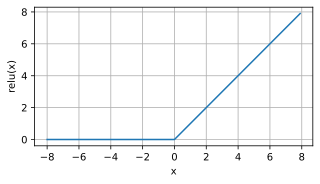

In [3]:
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.relu(x)
d2l.plot(x.detach(), y.detach(), 'x', 'relu(x)', figsize=(5, 2.5))

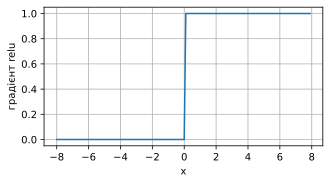

In [4]:
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'градієнт relu', figsize=(5, 2.5))

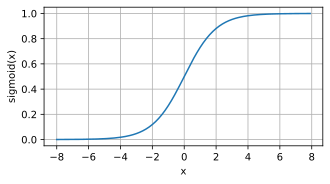

In [5]:
y = torch.sigmoid(x)
d2l.plot(x.detach(), y.detach(), 'x', 'sigmoid(x)', figsize=(5, 2.5))

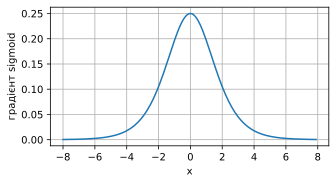

In [6]:
x.grad.zero_()
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'градієнт sigmoid', figsize=(5, 2.5))

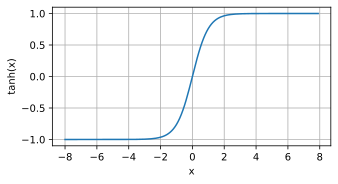

In [7]:
y = torch.tanh(x)
d2l.plot(x.detach(), y.detach(), 'x', 'tanh(x)', figsize=(5, 2.5))

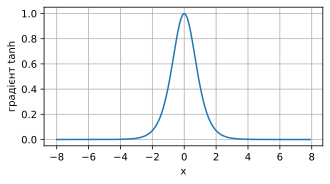

In [8]:
x.grad.zero_()
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'градієнт tanh', figsize=(5, 2.5))

In [9]:
import torch
from torch import nn
from d2l import torch as d2l

In [10]:
class MPLScratch(d2l.Classifier):
    def __init__(self, num_inputs, num_outputs, num_hiddens, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens) * sigma)
        self.b1 = nn.Parameter(torch.zeros(num_hiddens))
        self.W2 = nn.Parameter(torch.randn(num_hiddens, num_outputs) * sigma)
        self.b2 = nn.Parameter(torch.zeros(num_outputs))

In [11]:
def relu(X):
    a = torch.zeros_like(X)
    return torch.max(X, a)

In [12]:
def forward(self, X):
    X = X.reshape((-1, self.num_inputs))
    H = relu(torch.matmul(X, self.W1) + self.b1)
    return torch.matmul(H, self.W2) + self.b2

In [13]:
class MLP(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.LazyLinear(num_hiddens), nn.ReLU(), nn.LazyLinear(num_outputs))

In [14]:
model = MLP(num_outputs=10, num_hiddens=256, lr=0.1)
trainer.fit(model,data)

NameError: name 'trainer' is not defined

In [22]:
%matplotlib inline
import torch
from d2l import torch as d2l

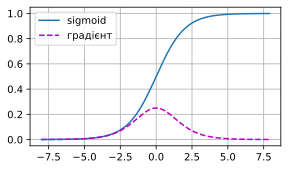

In [23]:
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.sigmoid(x)
y.backward(torch.ones_like(x))

d2l.plot(x.detach().numpy(), [y.detach().numpy(), x.grad.numpy()], legend=['sigmoid', 'градієнт'], figsize=(4.5, 2.5))

In [24]:
M = torch.normal(0, 1, size=(4, 4))
print('одна матриця \n', M)
for i in range(100):
    M = M @ torch.normal(0, 1, size=(4, 4))
    print('після множення 100 матриць\n', M)

одна матриця 
 tensor([[-0.7203, -1.2071, -0.1486, -0.0631],
        [-1.0068,  0.3581,  1.9568,  0.1664],
        [-1.3887,  1.4189, -1.0742,  0.5855],
        [ 0.5262, -0.4963, -2.2128, -1.0873]])
після множення 100 матриць
 tensor([[ 2.2391, -1.2593, -0.4747, -0.1001],
        [ 0.6461,  1.2790, -1.4709, -2.3336],
        [ 0.8101, -1.5094, -0.2831,  3.0780],
        [-0.2313, -1.5056,  2.7695,  1.7892]])
після множення 100 матриць
 tensor([[-0.9983,  2.2721,  4.4268, -3.7636],
        [ 1.6112,  3.0880,  5.5142, -4.2411],
        [-4.7001,  0.1088, -3.2339,  3.0761],
        [-0.0694, -3.8846, -4.5810,  2.9452]])
після множення 100 матриць
 tensor([[-4.9519,  1.5800, -1.6450, -2.8490],
        [-6.7381,  1.4736,  1.2763, -0.1923],
        [ 3.0389, -5.3434, -4.1384, -0.4180],
        [ 6.3908,  1.8414, -0.2369, -0.8485]])
після множення 100 матриць
 tensor([[  3.1388,   1.6354,  -2.0042,  -6.4710],
        [  5.8181,   7.7392,  -2.4137,  -8.2036],
        [ -3.4352,  -0.1669,   1.

In [15]:
M = torch.normal(0, 1, size=(4, 4))
print('одна матриця \n', M)
for i in range(100):
    M = M @ torch.normal(0, 1, size=(4, 4))
print('після множення 100 матриць\n', M)

одна матриця 
 tensor([[-0.6898,  0.5965,  0.1607, -0.3086],
        [-1.0965,  0.4366,  0.6467,  1.5349],
        [ 0.7609,  0.1419,  0.1891,  0.4175],
        [-0.9044,  0.6403,  0.6187,  0.1611]])
після множення 100 матриць
 tensor([[ 2.9724e+26, -1.9053e+27,  1.2081e+27, -6.3255e+26],
        [-6.3508e+24,  4.0708e+25, -2.5812e+25,  1.3515e+25],
        [-5.3083e+26,  3.4025e+27, -2.1575e+27,  1.1296e+27],
        [ 2.1696e+26, -1.3907e+27,  8.8182e+26, -4.6171e+26]])


In [16]:
import torch
from torch import nn
from d2l import torch as d2l


In [19]:
def dropout_layer(X, dropout):
    assert 0 <= dropout <= 1
    if dropout == 1: return torch.zeros_like(X)
    mask = (torch.rand(X.shape, device=X.device) > dropout).float()
    return X * mask / (1.0 - dropout)

In [20]:
X = torch.arange(16, dtype = torch.float32).reshape((2, 8))
print('dropout_p = 0', dropout_layer(X, 0))
print('dropout_p = 0.5', dropout_layer(X, 0.5))
print('dropout_p = 1', dropout_layer(X, 1))

dropout_p = 0 tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
dropout_p = 0.5 tensor([[ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.],
        [16.,  0.,  0.,  0., 24., 26., 28.,  0.]])
dropout_p = 1 tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


In [21]:
class DropoutMLPScratch(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens_1, num_hiddens_2, dropout_1, dropout_2, lr):
        super().__init__()
        self.save_hyperparameters()
        self.lin1 = nn.LazyLinear(num_hiddens_1)
        self.lin2 = nn.LazyLinear(num_hiddens_2)
        self.lin3 = nn.LazyLinear(num_outputs)
        self.relu = nn.ReLU()

    def forward(self, X):
        H1 = self.relu(self.lin1(X.reshape((X.shape[0], -1))))
        if self.training:
            H1 = dropout_layer(H1, self.dropout_1)
        H2 = self.relu(self.lin2(H1))
        if self.training:
            H2 = dropout_layer(H2, self.dropout_2)
        return self.lin3(H2)

In [ ]:
hparams = {'num_outputs':10, 'num_hiddens_1':256, 'num_hiddens_2':256, 'dropout_1':0.5, 'dropout_2':0.5, 'lr':0.1}
model = DropoutMLPScratch(**hparams)
data = d2l.FashionMNIST(batch_size=256)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)